<a href="https://colab.research.google.com/github/Barto12/ecobot-cdmx/blob/main/EcoBot_CDMX_Avance2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoBot CDMX — Avance de proyecto 2: PLN, visión por computadora e integración multimodal

**Desarrollo de Aplicaciones con Inteligencia Artificial (MBIA2602)** · Universidad Tecmilenio  
Alumno: Nazir Enoch Rosas Salgado · Profesor: Mackenson Polche  
Repositorio: https://github.com/Barto12/ecobot-cdmx

**Antes de ejecutar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)`. Luego `Entorno de ejecución → Ejecutar todas`. Con GPU tarda unos 5 minutos; sin GPU, unos 30.

## 0. Entorno y código del proyecto

In [1]:
import os, sys, platform, subprocess
if not os.path.exists('ecobot.py'):
    if not os.path.exists('ecobot-cdmx'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Barto12/ecobot-cdmx.git'], check=True)
    os.chdir('ecobot-cdmx')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm', 'nltk>=3.8'], check=True)
import torch, sklearn, nltk, timm
print('Python', platform.python_version(), '| PyTorch', torch.__version__, '| scikit-learn', sklearn.__version__,
      '| NLTK', nltk.__version__, '| timm', timm.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible (se usará CPU)')
print('Directorio:', os.getcwd())

Python 3.13.16 | PyTorch 2.14.1+cu130 | scikit-learn 1.6.1 | NLTK 3.9.1 | timm 1.0.31
GPU: Tesla T4
Directorio: /content/ecobot-cdmx


## 1. Conjunto de datos textual
Frases de entrenamiento por intención (manuales, por plantilla y con errores de tecleo simulados). Las 57 consultas de las pruebas del Avance 1 y 52 consultas nuevas quedan **fuera** del entrenamiento.

In [2]:
!python datos/generar_dataset_texto.py

Entrenamiento: 675 frases (11 descartadas por coincidir con pruebas)
  clasificar_residuo   182
  fuera_de_alcance     64
  dias_recoleccion     61
  preparacion          51
  normativa            43
  mercado_trueque      40
  reciclatron          40
  info_categoria       37
  colores              33
  agradecimiento       32
  ayuda                31
  despedida            31
  saludo               30
Origen: {'manual': 318, 'plantilla': 309, 'ruido': 48}
Prueba externa (Avance 1): 57   Prueba nueva: 52


In [3]:
import pandas as pd
pd.set_option('display.max_colwidth', 80)
entr = pd.read_csv('datos/intenciones_entrenamiento.csv')
display(entr.sample(12, random_state=1))
display(pd.crosstab(entr['intencion'], entr['origen'], margins=True))

,texto,intencion,origen
92,jornada de acopio de residuos electrónicos,reciclatron,manual
148,¿en cuál contenedor pnogo esta cosa?,clasificar_residuo,ruido
159,"oigan, ¿qué hago con las colillas?",clasificar_residuo,plantilla
460,nos vemos luego,despedida,manual
453,¿puedes ver fotos?,ayuda,manual
104,menú,ayuda,manual
172,¿dónde deposito el periódico viejo?,clasificar_residuo,plantilla
481,genial,agradecimiento,manual
57,¿quién descubrió améirca?,fuera_de_alcance,ruido
415,¿qué recibe el mercado de trueque?,mercado_trueque,manual


origen,manual,plantilla,ruido,All
intencion,,,,
agradecimiento,28,0,4,32
ayuda,27,0,4,31
clasificar_residuo,20,159,3,182
colores,10,22,1,33
despedida,28,0,3,31
dias_recoleccion,18,38,5,61
fuera_de_alcance,52,0,12,64
info_categoria,12,24,1,37
mercado_trueque,27,10,3,40


## 2. Preprocesamiento de texto (NLTK)
Normalización → tokenización → eliminación de *stopwords* (lista adaptada) → *stemming* Snowball.

In [4]:
from clasificador_texto import etapas, STOPWORDS_ADAPTADA, STOPWORDS_NLTK
for frase in ['¿Dónde tiro las botellas de plástico?', 'Oye, ¿qué días pasan por los orgánicos?',
              '¿Hay que lavar los frascos antes de reciclarlos?', 'Nos vemos, muy amable']:
    e = etapas(frase)
    print(f"Original     : {e['original']}\nNormalizado  : {e['normalizado']}\nTokens       : {e['tokens']}\n"
          f"Sin stopwords: {e['sin_stopwords']}\nRaíces       : {e['raices']}\n")
print(f'Stopwords: {len(STOPWORDS_ADAPTADA)} de las {len(STOPWORDS_NLTK)} de NLTK ->', sorted(STOPWORDS_ADAPTADA))

Original     : ¿Dónde tiro las botellas de plástico?
Normalizado  : donde tiro las botellas de plastico
Tokens       : ['donde', 'tiro', 'las', 'botellas', 'de', 'plastico']
Sin stopwords: ['donde', 'tiro', 'botellas', 'plastico']
Raíces       : ['donde', 'tir', 'botell', 'plastic']

Original     : Oye, ¿qué días pasan por los orgánicos?
Normalizado  : oye   que dias pasan por los organicos
Tokens       : ['oye', 'que', 'dias', 'pasan', 'por', 'los', 'organicos']
Sin stopwords: ['oye', 'que', 'dias', 'pasan', 'por', 'organicos']
Raíces       : ['oye', 'que', 'dias', 'pas', 'por', 'organ']

Original     : ¿Hay que lavar los frascos antes de reciclarlos?
Normalizado  : hay que lavar los frascos antes de reciclarlos
Tokens       : ['hay', 'que', 'lavar', 'los', 'frascos', 'antes', 'de', 'reciclarlos']
Sin stopwords: ['hay', 'que', 'lavar', 'frascos', 'antes', 'reciclarlos']
Raíces       : ['hay', 'que', 'lav', 'frasc', 'antes', 'recicl']

Original     : Nos vemos, muy amable
Normalizado  

## 3. Representación y clasificación de intenciones
TF-IDF y Bag of Words × Naive Bayes y SVM lineal, con validación cruzada de 5 particiones; ablación del preprocesamiento; umbral de confianza; evaluación final en los dos conjuntos de prueba.

In [5]:
!python entrenar_texto.py 2>&1 | grep -v Warning

Vocabulario: {'sin_preprocesamiento': 646, 'normalizacion': 600, 'normalizacion_stopwords': 582, 'completo': 486}
{'representacion': 'TF-IDF', 'clasificador': 'Naive Bayes', 'hiperparametro': '{"alpha": 0.1}', 'cv_accuracy': np.float64(0.8222), 'cv_f1_macro': np.float64(0.8125), 'cv_f1_macro_std': np.float64(0.0289), 'externa_accuracy': 0.9649, 'nueva_accuracy': 0.9423, 'nueva_f1_macro': 0.9414}
{'representacion': 'TF-IDF', 'clasificador': 'SVM lineal', 'hiperparametro': '{"C": 3.0}', 'cv_accuracy': np.float64(0.877), 'cv_f1_macro': np.float64(0.8564), 'cv_f1_macro_std': np.float64(0.0359), 'externa_accuracy': 0.9474, 'nueva_accuracy': 0.9423, 'nueva_f1_macro': 0.9417}
{'representacion': 'Bag of Words', 'clasificador': 'Naive Bayes', 'hiperparametro': '{"alpha": 0.05}', 'cv_accuracy': np.float64(0.8326), 'cv_f1_macro': np.float64(0.82), 'cv_f1_macro_std': np.float64(0.0283), 'externa_accuracy': 0.9298, 'nueva_accuracy': 0.9231, 'nueva_f1_macro': 0.9185}
{'representacion': 'Bag of Words

In [6]:
ev = 'evidencias/avance2/'
display(pd.read_csv(ev + 'texto_comparacion_modelos.csv'))
display(pd.read_csv(ev + 'texto_ablacion.csv'))
display(pd.read_csv(ev + 'texto_reporte_por_clase.csv', index_col=0))

,representacion,clasificador,hiperparametro,cv_accuracy,cv_f1_macro,cv_f1_macro_std,externa_accuracy,nueva_accuracy,nueva_f1_macro
0,TF-IDF,Naive Bayes,"{""alpha"": 0.1}",0.8222,0.8125,0.0289,0.9649,0.9423,0.9414
1,TF-IDF,SVM lineal,"{""C"": 3.0}",0.8770,0.8564,0.0359,0.9474,0.9423,0.9417
2,Bag of Words,Naive Bayes,"{""alpha"": 0.05}",0.8326,0.8200,0.0283,0.9298,0.9231,0.9185
3,Bag of Words,SVM lineal,"{""C"": 1.0}",0.8859,0.8622,0.0356,0.8596,0.9038,0.9043


,configuracion,cv_f1_macro,nueva_accuracy,externa_accuracy
0,"Completo, stopwords adaptadas (final)",0.8622,0.9038,0.8596
1,"Completo, stopwords NLTK sin adaptar",0.8149,0.8846,0.8421
2,Sin eliminar stopwords,0.8625,0.9231,0.8947
3,Sin stemming,0.8560,0.9231,0.8772
4,Sin normalización,0.8670,0.8654,0.9123
5,Solo tokenización,0.8577,0.9038,0.8947


,precision,recall,f1-score,support
agradecimiento,1.000,0.875,0.933,8.00
ayuda,1.000,1.000,1.000,5.00
clasificar_residuo,0.923,0.800,0.857,30.00
colores,1.000,0.667,0.800,6.00
despedida,1.000,0.833,0.909,6.00
dias_recoleccion,1.000,1.000,1.000,9.00
fuera_de_alcance,0.462,0.857,0.600,7.00
info_categoria,1.000,1.000,1.000,6.00
mercado_trueque,1.000,1.000,1.000,6.00
normativa,1.000,1.000,1.000,7.00


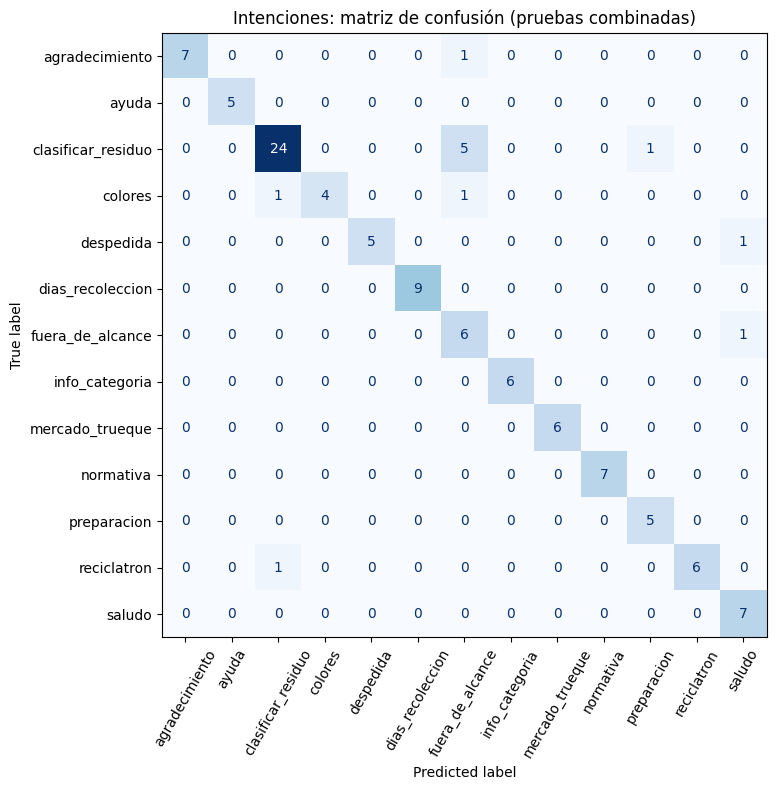

prueba_externa — errores:


,texto,intencion,prediccion,confianza
9,¿Y el periódico?,clasificar_residuo,fuera_de_alcance,0.323
13,¿Los pañales?,clasificar_residuo,fuera_de_alcance,0.341
18,y las latas de atun,clasificar_residuo,fuera_de_alcance,0.319
19,ok grax,agradecimiento,fuera_de_alcance,0.280
21,unas pilas,clasificar_residuo,fuera_de_alcance,0.338
42,tengo una laptop vieja,clasificar_residuo,fuera_de_alcance,0.184
45,¿Puedo tirar el aceite por el fregadero?,clasificar_residuo,preparacion,0.681
49,¿Qué contenedor es el naranja?,colores,clasificar_residuo,0.497


prueba_nueva — errores:


,texto,intencion,prediccion,confianza
15,¿qué se pone en el café?,colores,fuera_de_alcance,0.623
21,¿dónde dejo una impresora vieja para reciclar?,reciclatron,clasificar_residuo,0.633
36,"bueno, adiós",despedida,saludo,0.558
48,¿dónde venden tacos buenos?,fuera_de_alcance,saludo,0.553


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
cm = pd.read_csv(ev + 'texto_matriz_confusion.csv', index_col=0)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm.values, display_labels=cm.columns).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=60)
ax.set_title('Intenciones: matriz de confusión (pruebas combinadas)'); plt.tight_layout(); plt.show()
for n in ['prueba_externa', 'prueba_nueva']:
    d = pd.read_csv(ev + f'texto_predicciones_{n}.csv')
    print(n, '— errores:'); display(d.loc[~d['correcto'], ['texto', 'intencion', 'prediccion', 'confianza']])

## 4. Conjunto de imágenes y clasificador visual (CNN con transferencia de aprendizaje)
TrashNet (2,527 fotos, 6 materiales). Se comparan EfficientNet-B0 y ResNet50 congeladas con cabeza lineal, y EfficientNet-B0 con ajuste fino de sus 2 últimos bloques. El modelo final se elige en validación.

In [8]:
import torch
!python entrenar_imagen.py --epocas 8

18:34:14 Dispositivo: cuda
18:34:14 Descargando TrashNet (43 MB)…
18:34:17 Partición:
           entrenamiento  validacion  prueba  total
cardboard            282          61      60    403
glass                350          75      76    501
metal                287          61      62    410
paper                416          89      89    594
plastic              337          72      73    482
trash                 96          21      20    137
Downloading: "https://github.com/huggingface/pytorch-image-models/releases/download/v0.1-weights/efficientnet_b0_ra-3dd342df.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_ra-3dd342df.pth
18:34:18 [A:efficientnet_b0] extrayendo características…
18:35:10 [A:efficientnet_b0] C=0.01  F1 val=0.8371
18:35:15 [A:efficientnet_b0] C=0.03  F1 val=0.8491
18:35:21 [A:efficientnet_b0] C=0.1  F1 val=0.8624
18:35:25 [A:efficientnet_b0] C=0.3  F1 val=0.8646
18:35:28 [A:efficientnet_b0] C=1.0  F1 val=0.8647
18:35:32 [A:efficientnet_b0] {'descripcio

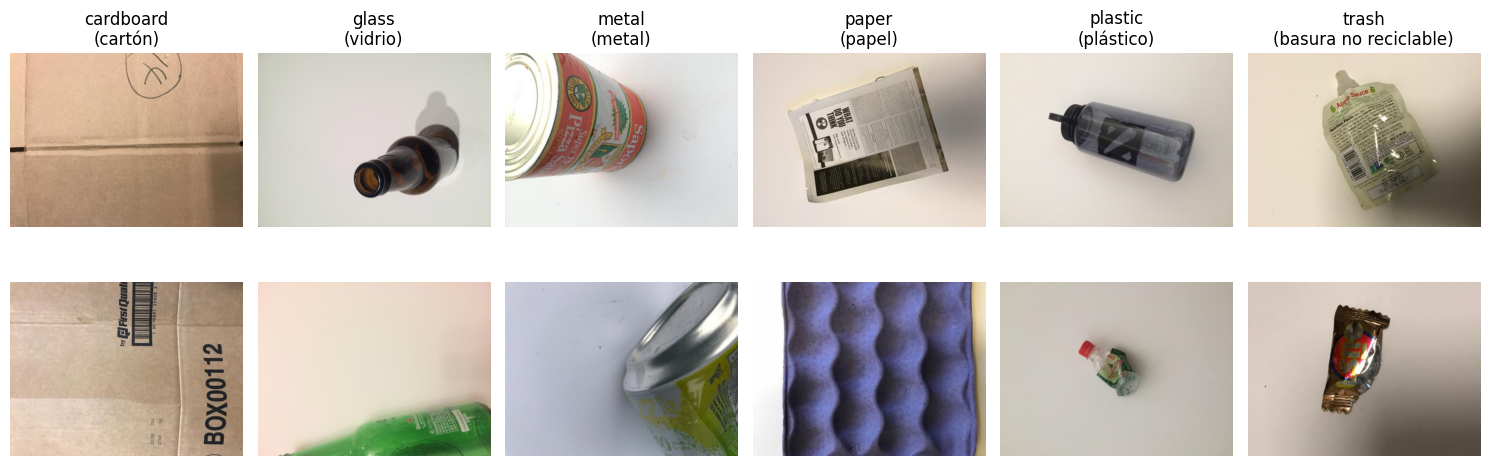

,entrenamiento,validacion,prueba,total
cardboard,282,61,60,403
glass,350,75,76,501
metal,287,61,62,410
paper,416,89,89,594
plastic,337,72,73,482
trash,96,21,20,137


In [9]:
from PIL import Image
from pathlib import Path
from clasificador_imagen import CLASES, NOMBRE_ES
raiz = Path('datos_imagenes/dataset-resized')
fig, ejes = plt.subplots(2, 6, figsize=(15, 5.5))
for j, c in enumerate(CLASES):
    for i, f in enumerate(sorted((raiz / c).glob('*.jpg'))[:2]):
        ejes[i, j].imshow(Image.open(f)); ejes[i, j].axis('off')
    ejes[0, j].set_title(f'{c}\n({NOMBRE_ES[c]})')
plt.tight_layout(); plt.show()
display(pd.read_csv(ev + 'imagen_conteos.csv', index_col=0))

,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
A_efficientnet_b0,0.8892,0.8779,0.8567,0.8647,0.8763,0.8631,0.8578,0.8594
A_resnet50,0.8971,0.8963,0.8934,0.8943,0.8789,0.8629,0.8547,0.8565
B_efficientnet_b0,0.8997,0.8722,0.8804,0.8754,0.8605,0.8334,0.8551,0.8419


Modelo final (elegido en validación): A_resnet50 | umbral de confianza: 0.8


,epoca,perdida_entrenamiento,accuracy_entrenamiento,accuracy_validacion,f1_validacion
0,1,1.0896,0.7981,0.8417,0.8182
1,2,0.7709,0.8971,0.8575,0.8436
2,3,0.6449,0.9548,0.8707,0.8478
3,4,0.6206,0.9672,0.8892,0.8666
4,5,0.5823,0.9802,0.8971,0.8732
5,6,0.5720,0.9853,0.8918,0.8668
6,7,0.5650,0.9876,0.8945,0.8741
7,8,0.5575,0.9876,0.8997,0.8754


,precision,recall,f1-score,support
cardboard,0.8689,0.8833,0.8760,60.0000
glass,0.8961,0.9079,0.9020,76.0000
metal,0.8219,0.9677,0.8889,62.0000
paper,0.9494,0.8427,0.8929,89.0000
plastic,0.8767,0.8767,0.8767,73.0000
trash,0.7647,0.6500,0.7027,20.0000
accuracy,0.8789,0.8789,0.8789,0.8789
macro avg,0.8629,0.8547,0.8565,380.0000
weighted avg,0.8815,0.8789,0.8783,380.0000


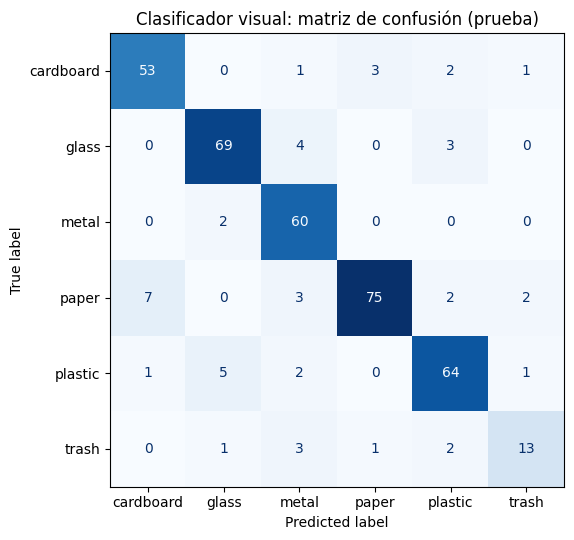

In [10]:
import json
res = json.load(open(ev + 'imagen_resumen.json'))
display(pd.DataFrame({k: {**{'val_' + m: v for m, v in r['validacion'].items()}, **{'test_' + m: v for m, v in r['prueba'].items()}}
                      for k, r in res['experimentos'].items()}).T)
print('Modelo final (elegido en validación):', res['modelo_final'], '| umbral de confianza:', res['umbral_confianza'])
display(pd.read_csv(ev + 'imagen_historia_finetuning.csv'))
display(pd.read_csv(ev + 'imagen_reporte_por_clase.csv', index_col=0))
cm = pd.read_csv(ev + 'imagen_matriz_confusion.csv', index_col=0)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm.values, display_labels=cm.columns).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Clasificador visual: matriz de confusión (prueba)'); plt.tight_layout(); plt.show()

## 5. Integración texto-imagen
El bot recibe texto, foto o ambos: (1) procesa el texto, (2) clasifica la imagen y (3) interpreta el material con la base de conocimiento NADF-024 y lo comunica, pidiendo confirmación si la confianza es baja.

In [11]:
!python evaluar_integracion.py datos_imagenes/dataset-resized 2>&1 | grep -v Warning

      conjunto  consultas  reglas_avance1  clasificador  hibrido
prueba_externa         57          0.9649        0.8596   0.9649
  prueba_nueva         52          0.6346        0.9231   0.9231
{
  "fotos": 380,
  "material_correcto": 0.8789,
  "categoria_correcta_si_se_clasifica_todo": 0.9711,
  "respondidas_directo": 301,
  "categoria_correcta_en_respondidas": 0.9867,
  "material_correcto_en_respondidas": 0.9468,
  "pide_confirmacion": 79,
  "en_dudosas_top1_correcto": 49,
  "en_dudosas_real_en_top3": 76
}
EcoBot CDMX multimodal — conversaciones de demostración

D1 · Foto + pregunta de clasificación
------------------------------------------------------------------------
Usuario: ¿dónde tiro esto?   [imagen: glass68.jpg]
  ↳ intención=clasificar_residuo (conf. 0.90) | imagen=glass (p=1.00) | regla=clasificación por imagen
EcoBot: En la foto veo vidrio (100% de confianza). Vidrio → INORGÁNICOS RECICLABLES (contenedor gris). Se recoge lunes, miércoles, viernes y domingo. Entrégalos li

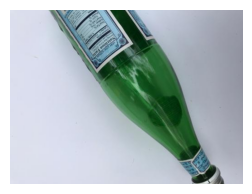

Usuario: ¿dónde tiro esto? [foto]
EcoBot : En la foto veo vidrio (100% de confianza). Vidrio → INORGÁNICOS RECICLABLES (contenedor gris). Se recoge lunes, miércoles, viernes y domingo. Entrégalos limpios y secos: enjuaga envases, aplasta botellas y cajas para que ocupen menos espacio. 



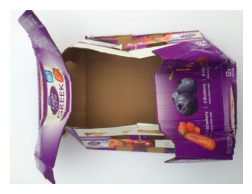

Usuario: ¿qué día pasan por esto? [foto]
EcoBot : En la foto veo cartón (98%). Inorgánicos reciclables se recogen lunes, miércoles, viernes y domingo. Los días de recolección pueden variar por alcaldía y ruta; confirma con el servicio de limpia de tu colonia. 



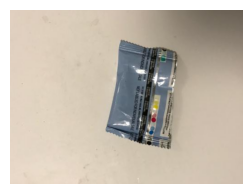

Usuario: ¿esto se recicla? [foto]
EcoBot : En la foto veo basura no reciclable (88% de confianza). Parece un residuo de aprovechamiento limitado → INORGÁNICOS NO RECICLABLES (contenedor naranja). Se recoge lunes, miércoles, viernes y domingo. Si en realidad es un envase limpio de plástico, vidrio, metal o cartón, va con los reciclables. 



In [12]:
from ecobot_multimodal import EcoBotMultimodal
bot = EcoBotMultimodal()
pred = pd.read_csv(ev + 'imagen_predicciones_prueba.csv')
for c, pregunta in [('glass', '¿dónde tiro esto?'), ('cardboard', '¿qué día pasan por esto?'), ('trash', '¿esto se recicla?')]:
    f = raiz / c / pred[(pred.real == c) & (pred.prediccion == c)].iloc[0]['archivo']
    plt.figure(figsize=(3, 2.3)); plt.imshow(Image.open(f)); plt.axis('off'); plt.show()
    print('Usuario:', pregunta, '[foto]')
    print('EcoBot :', bot.responder(pregunta, f), '\n')

## 6. Prueba con tu propia foto
Sube una foto de un residuo y escribe una pregunta.

Saving bottle.jpg to bottle.jpg


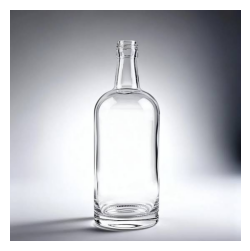

Tu pregunta sobre la foto: ¿dónde tiro esto?
EcoBot: En la foto veo vidrio (98% de confianza). Vidrio → INORGÁNICOS RECICLABLES (contenedor gris). Se recoge lunes, miércoles, viernes y domingo. Entrégalos limpios y secos: enjuaga envases, aplasta botellas y cajas para que ocupen menos espacio.


In [13]:
import sys
if 'google.colab' in sys.modules:
    from google.colab import files
    subida = files.upload()
    for nombre in subida:
        plt.figure(figsize=(3, 3)); plt.imshow(Image.open(nombre)); plt.axis('off'); plt.show()
        pregunta = input('Tu pregunta sobre la foto: ')
        print('EcoBot:', bot.responder(pregunta, nombre))
else:
    print('Disponible al ejecutar en Google Colab.')

In [14]:
   !zip -qr evidencias_avance2.zip evidencias/avance2
   from google.colab import files
   files.download('evidencias_avance2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>